# ML-Practical-7

## Name:Shubh Veerwani
## Class:B_B3
## Roll No:34

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import(accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix)

pd.set_option('display.max_columns',None)

In [2]:
df=pd.read_excel("Raisin_Dataset.xlsx")

In [3]:
target = "Class"
features = df.select_dtypes(include=np.number).columns.drop("Class_encoded", errors="ignore").tolist()
print("Target  :", target)
print("Features:", features)

Target  : Class
Features: ['Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity', 'ConvexArea', 'Extent', 'Perimeter']


In [4]:
df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen


In [5]:
df.tail()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
895,83248,430.077308,247.838695,0.817263,85839,0.668793,1129.072,Besni
896,87350,440.735698,259.293149,0.808629,90899,0.636476,1214.252,Besni
897,99657,431.706981,298.837323,0.721684,106264,0.741099,1292.828,Besni
898,93523,476.344094,254.176054,0.845739,97653,0.658798,1258.548,Besni
899,85609,512.081774,215.271976,0.907345,89197,0.632020,1272.862,Besni


In [6]:
df.shape

(900, 8)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             900 non-null    int64  
 1   MajorAxisLength  900 non-null    float64
 2   MinorAxisLength  900 non-null    float64
 3   Eccentricity     900 non-null    float64
 4   ConvexArea       900 non-null    int64  
 5   Extent           900 non-null    float64
 6   Perimeter        900 non-null    float64
 7   Class            900 non-null    object 
dtypes: float64(5), int64(2), object(1)
memory usage: 56.4+ KB


In [8]:
df.describe()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
count,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000
mean,87804.127778,430.929950,254.488133,0.781542,91186.090000,0.699508,1165.906636
std,39002.111390,116.035121,49.988902,0.090318,40769.290132,0.053468,273.764315
min,25387.000000,225.629541,143.710872,0.348730,26139.000000,0.379856,619.074000
25%,59348.000000,345.442898,219.111126,0.741766,61513.250000,0.670869,966.410750
50%,78902.000000,407.803951,247.848409,0.798846,81651.000000,0.707367,1119.509000
75%,105028.250000,494.187014,279.888575,0.842571,108375.750000,0.734991,1308.389750
max,235047.000000,997.291941,492.275279,0.962124,278217.000000,0.835455,2697.753000


In [9]:
df.isnull().sum()

Area               0
MajorAxisLength    0
MinorAxisLength    0
Eccentricity       0
ConvexArea         0
Extent             0
Perimeter          0
Class              0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.columns

Index(['Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity',
       'ConvexArea', 'Extent', 'Perimeter', 'Class'],
      dtype='object')

# 1. Univariate Analysis

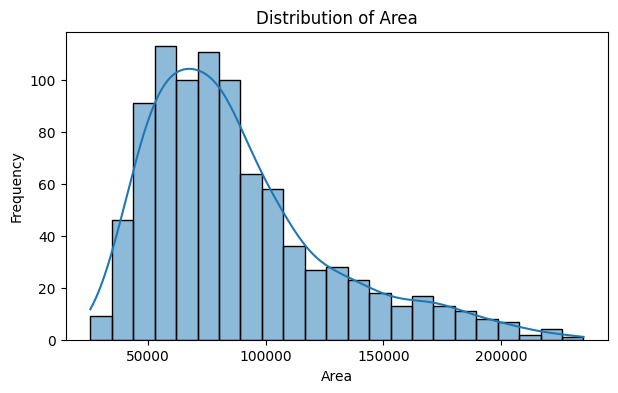

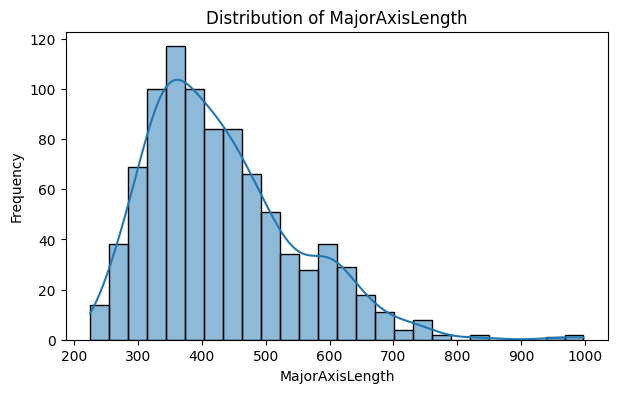

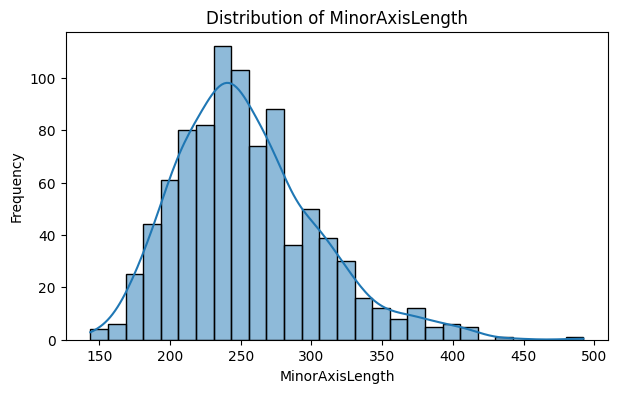

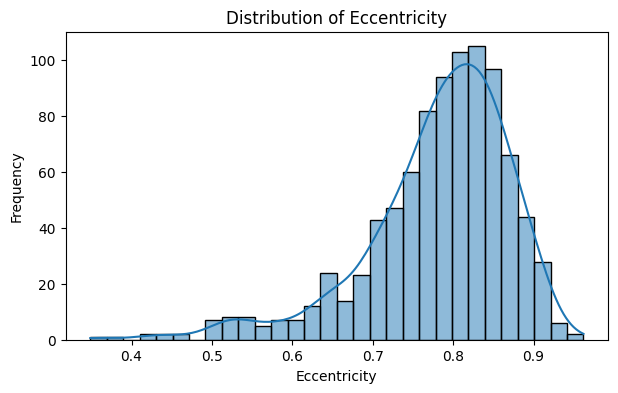

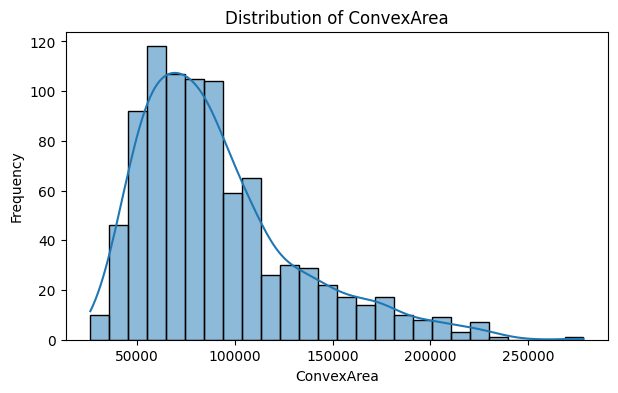

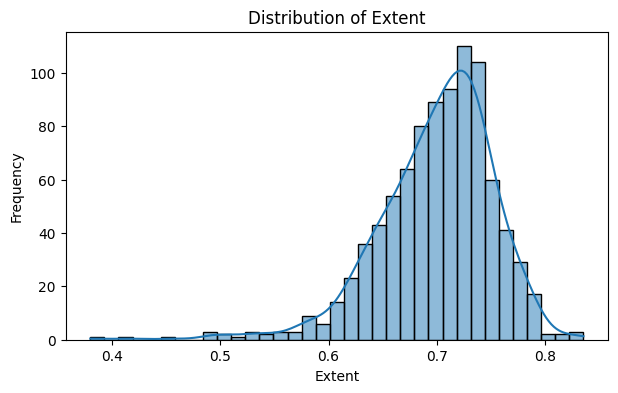

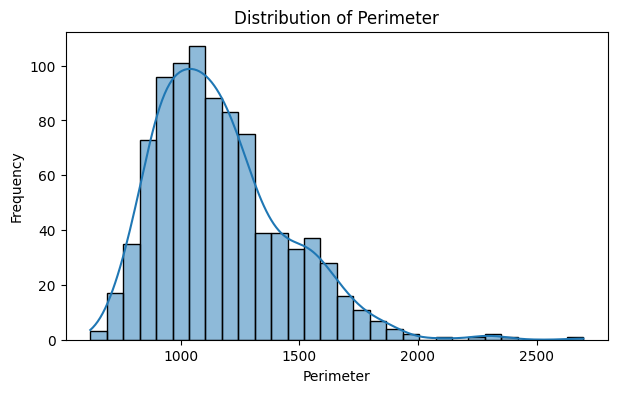

In [12]:
# Histogram + KDE
for col in features:
    plt.figure(figsize=(7,4))
    sns.histplot(df[col], kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

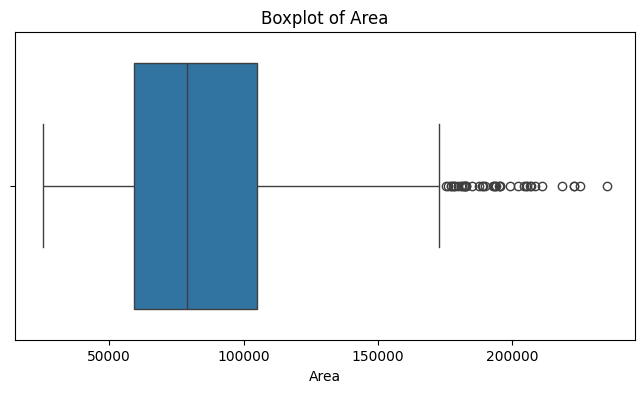

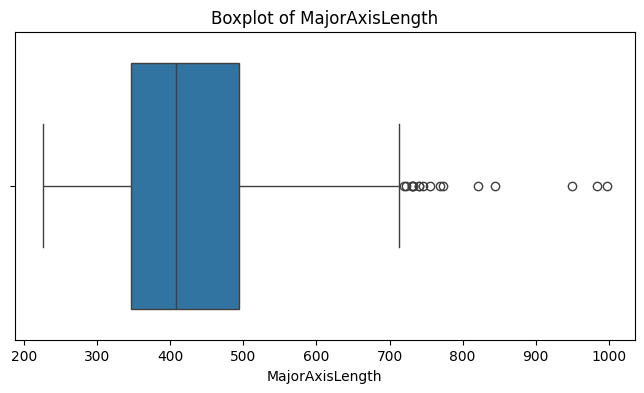

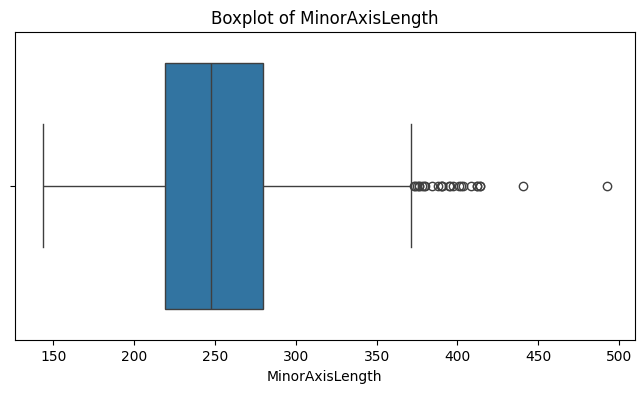

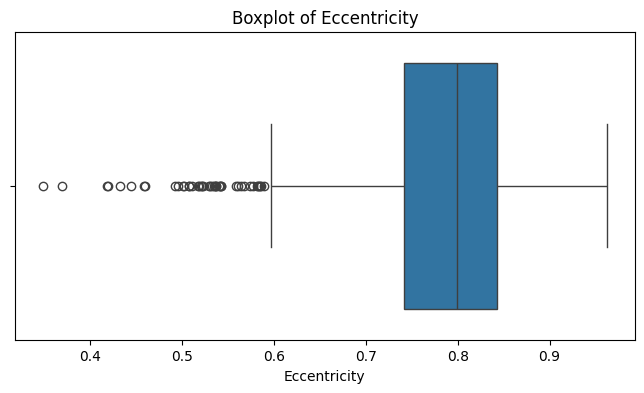

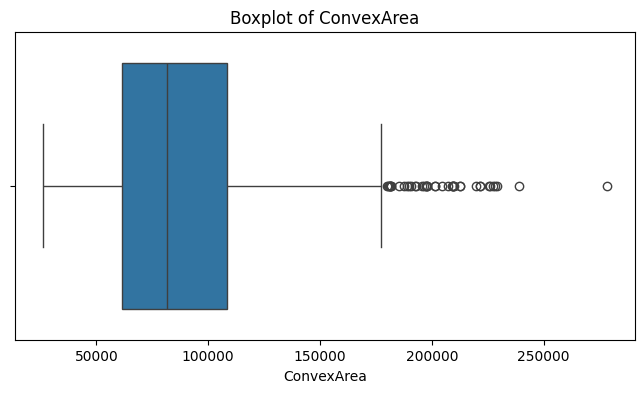

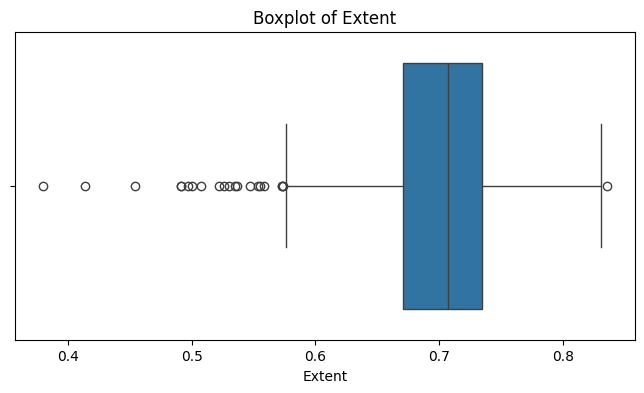

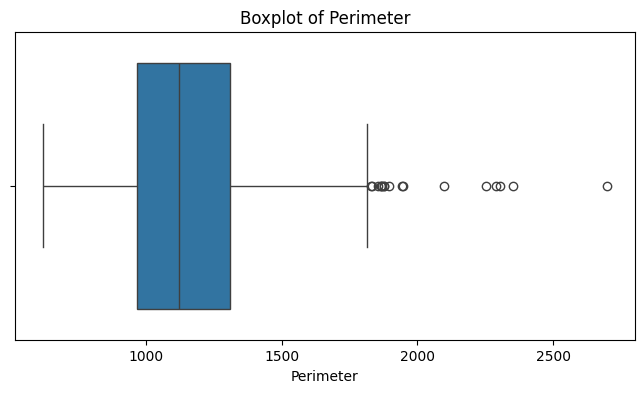

In [13]:
# Boxplot - Outlier Analysis
for col in features:
    plt.figure(figsize=(8,4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [14]:
# Skewness and kurtosis
pd.DataFrame({"Skewness": df[features].skew(), "Kurtosis": df[features].kurtosis()}).round(3)

,Skewness,Kurtosis
Area,1.175,1.074
MajorAxisLength,0.990,1.327
MinorAxisLength,0.800,0.954
Eccentricity,-1.328,2.492
ConvexArea,1.243,1.427
Extent,-1.152,3.341
Perimeter,1.018,1.745


In [15]:
# Detect outliers for every feature using the IQR rule
feat_df = df[features]

Q1 = feat_df.quantile(0.25)
Q3 = feat_df.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5*IQR
upper_bound = Q3 + 1.5*IQR

outlier_mask = (feat_df < lower_bound) | (feat_df > upper_bound)
outlier_count = outlier_mask.sum()
outlier_percentage = (outlier_count/len(feat_df))*100

outlier_summary = pd.DataFrame({
    'Q1': Q1,
    'Q3': Q3,
    'IQR': IQR,
    'lower bound': lower_bound,
    'upper bound': upper_bound,
    'Outlier Count': outlier_count,
    'Outlier %': outlier_percentage
})

outlier_summary.round(3)

,Q1,Q3,IQR,lower bound,upper bound,Outlier Count,Outlier %
Area,59348.000,105028.250,45680.250,-9172.375,173548.625,41,4.556
MajorAxisLength,345.443,494.187,148.744,122.327,717.303,17,1.889
MinorAxisLength,219.111,279.889,60.777,127.945,371.055,26,2.889
Eccentricity,0.742,0.843,0.101,0.591,0.994,43,4.778
ConvexArea,61513.250,108375.750,46862.500,-8780.500,178669.500,42,4.667
Extent,0.671,0.735,0.064,0.575,0.831,21,2.333
Perimeter,966.411,1308.390,341.979,453.442,1821.358,17,1.889


In [16]:
# No of outliers in each feature
print("Outliers in each feature:\n")

for column in feat_df.columns:
    print(f"{column:25s}:{outlier_count[column]}")

Outliers in each feature:

Area                     :41
MajorAxisLength          :17
MinorAxisLength          :26
Eccentricity             :43
ConvexArea               :42
Extent                   :21
Perimeter                :17


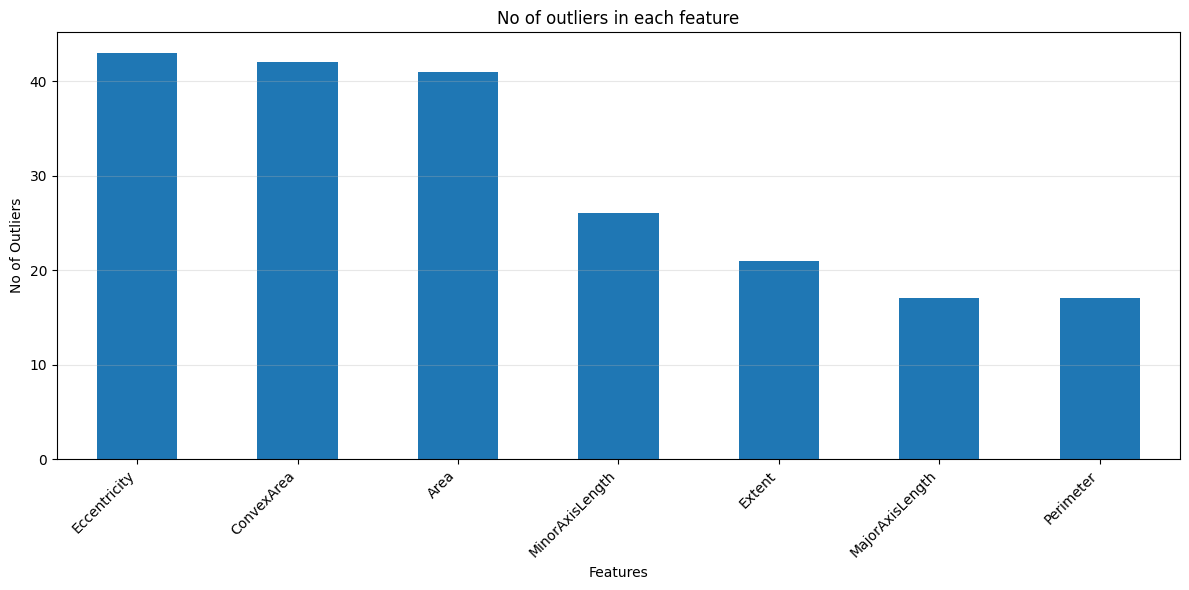

In [17]:
plt.figure(figsize=(12,6))

outlier_count.sort_values(ascending=False).plot(kind='bar')

plt.title("No of outliers in each feature")
plt.xlabel("Features")
plt.ylabel("No of Outliers")
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

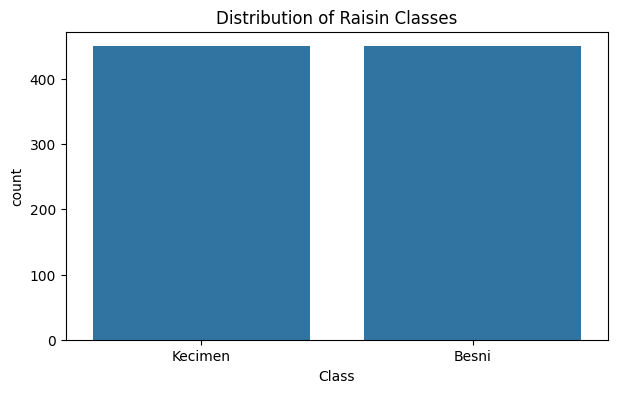

In [18]:
# Class Distribution
plt.figure(figsize=(7,4))
sns.countplot(x=target, data=df)
plt.title("Distribution of Raisin Classes")
plt.show()

In [19]:
print(df[target].value_counts())
print()
print(df[target].value_counts(normalize=True).round(3))

Class
Kecimen    450
Besni      450
Name: count, dtype: int64

Class
Kecimen    0.5
Besni      0.5
Name: proportion, dtype: float64


# 2. Bivariate Analysis

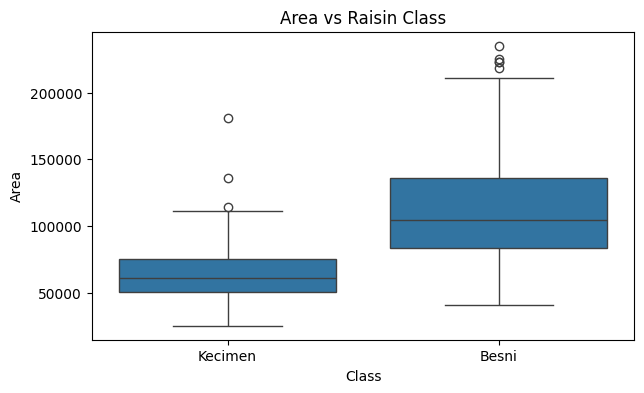

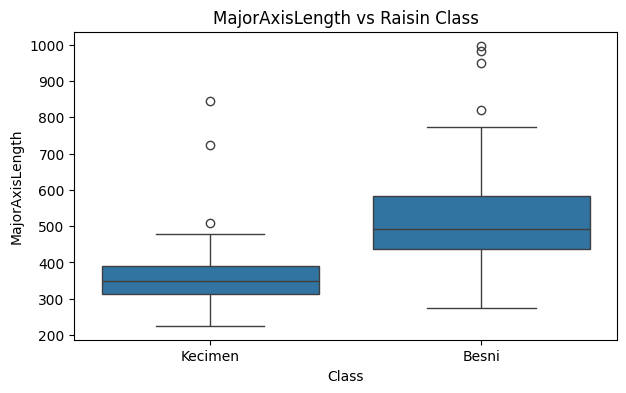

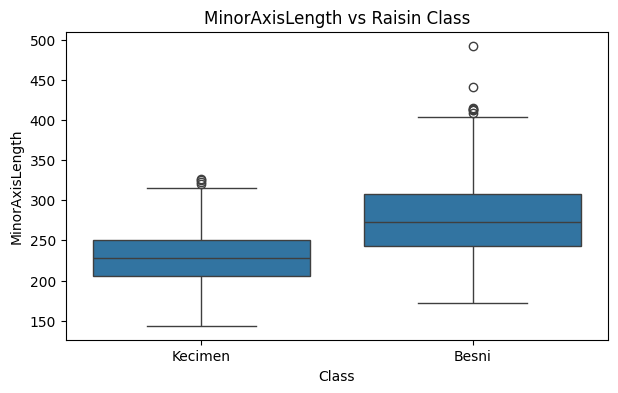

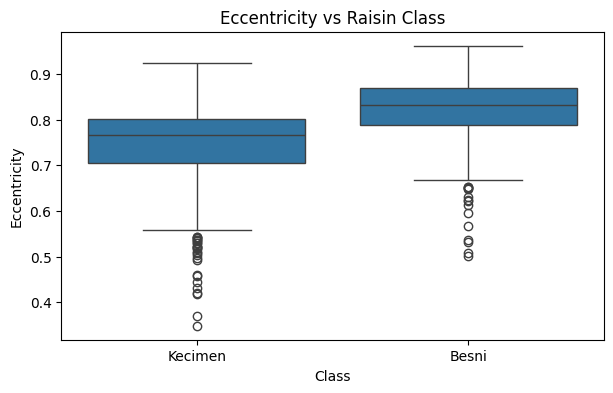

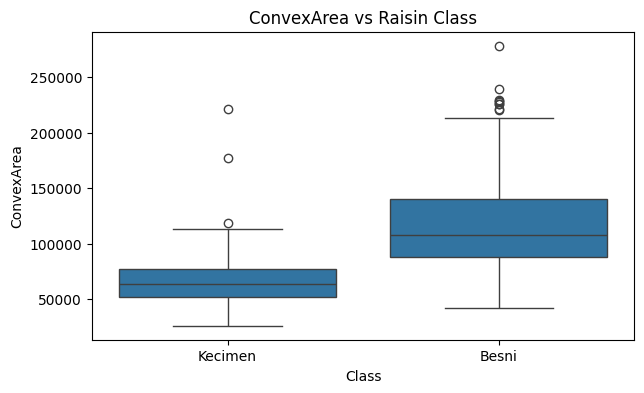

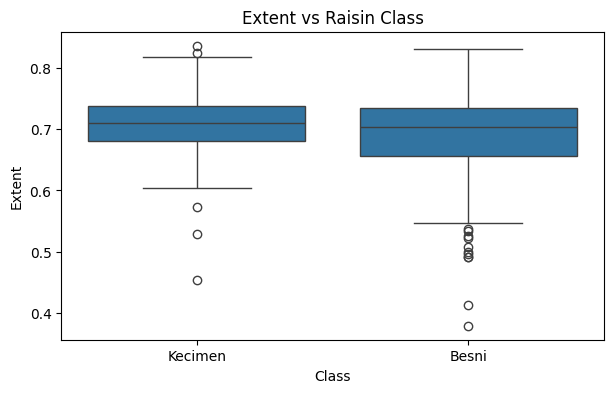

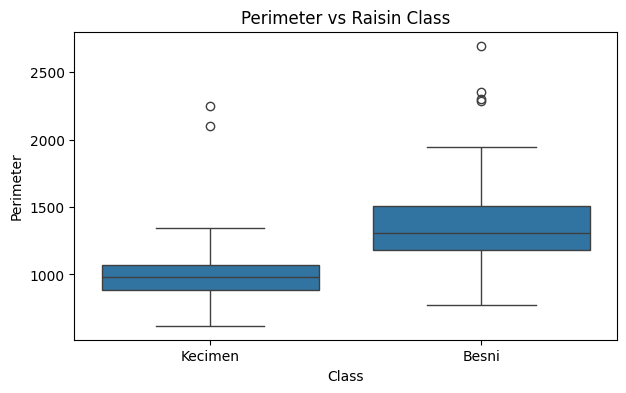

In [20]:
# Every feature vs Class
for col in features:
    plt.figure(figsize=(7,4))
    sns.boxplot(x=target, y=col, data=df)
    plt.title(f'{col} vs Raisin Class')
    plt.show()

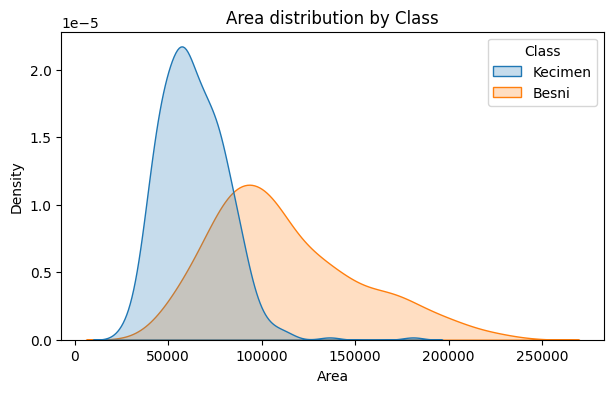

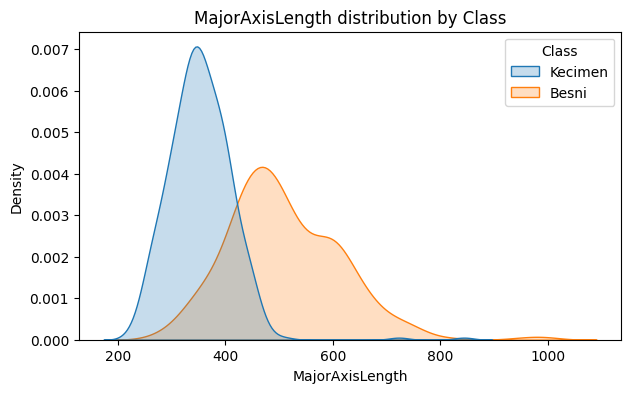

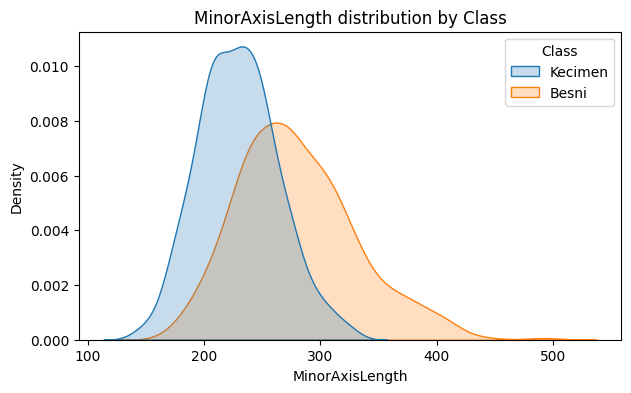

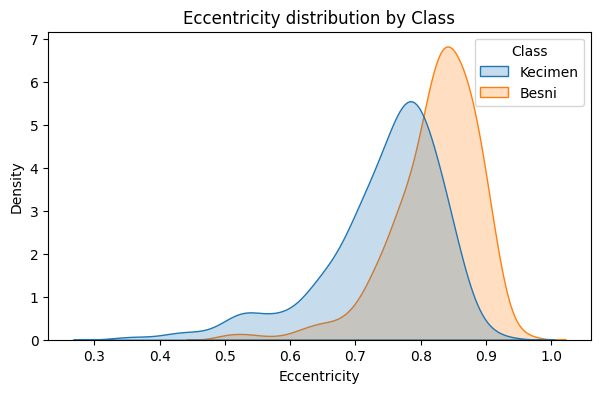

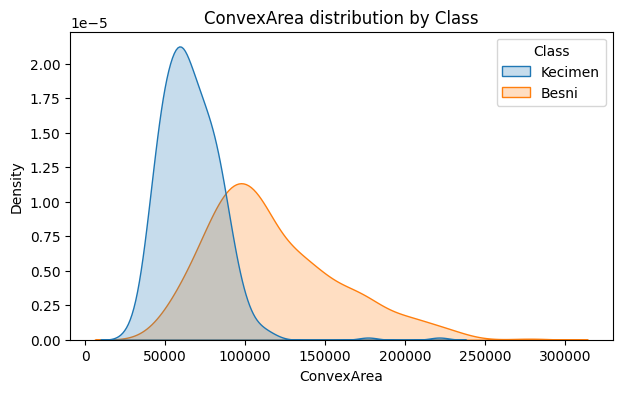

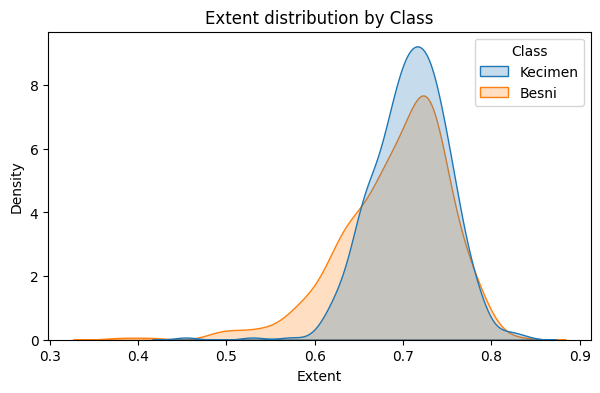

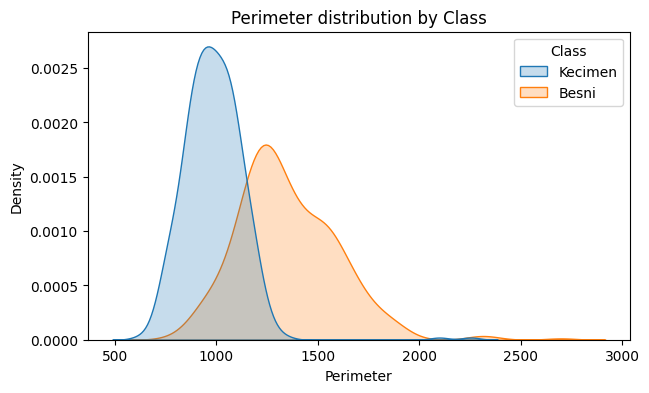

In [21]:
# Overlapping distributions by class
for col in features:
    plt.figure(figsize=(7,4))
    sns.kdeplot(data=df, x=col, hue=target, fill=True, common_norm=False)
    plt.title(f'{col} distribution by Class')
    plt.show()

In [22]:
# Class-wise mean of every feature
df.groupby(target)[features].mean().round(3)

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
Class,,,,,,,
Besni,112194.789,509.001,279.624,0.821,116675.824,0.691,1348.127
Kecimen,63413.467,352.859,229.353,0.742,65696.356,0.708,983.686


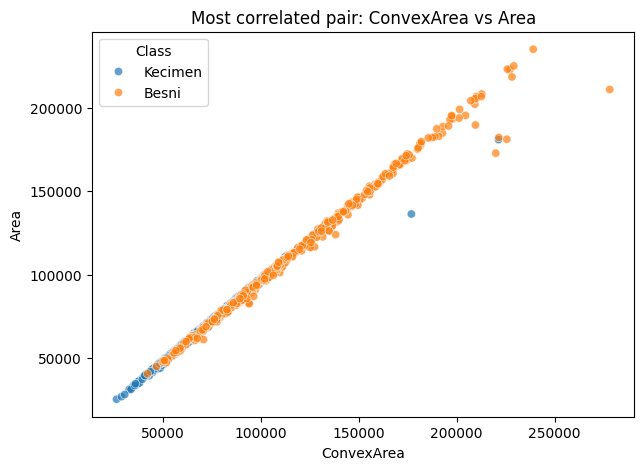

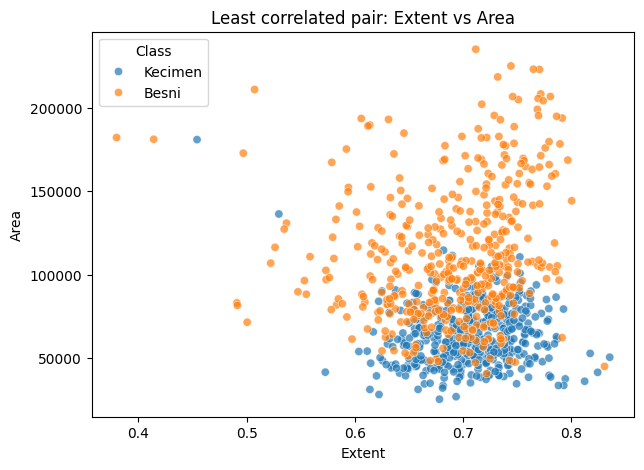

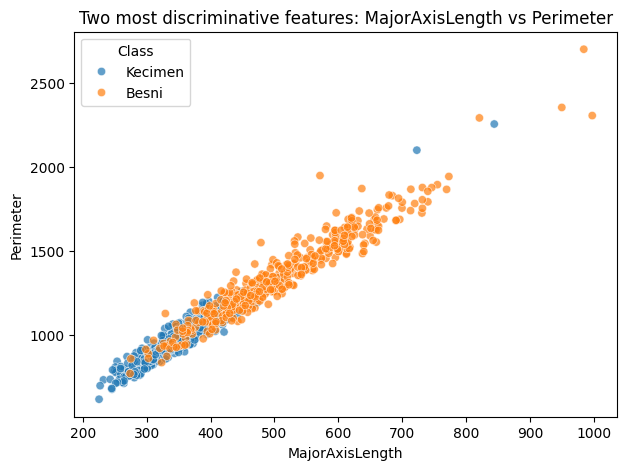

In [24]:
# Scatter plots: most correlated pair, least correlated pair, two most discriminative features
corr_f = df[features].corr()
mask = np.triu(np.ones_like(corr_f, dtype=bool))
pair_corr = corr_f.where(~mask).stack()

most_pair = pair_corr.abs().idxmax()
least_pair = pair_corr.abs().idxmin()
top2 = anova.index[:2].tolist()

for (a, b), title in [(most_pair, "Most correlated pair"),
                      (least_pair, "Least correlated pair"),
                      (tuple(top2), "Two most discriminative features")]:
    plt.figure(figsize=(7,5))
    sns.scatterplot(x=a, y=b, hue=target, data=df, alpha=0.7)
    plt.title(f"{title}: {a} vs {b}")
    plt.show()

# 3. Multivariate Analysis

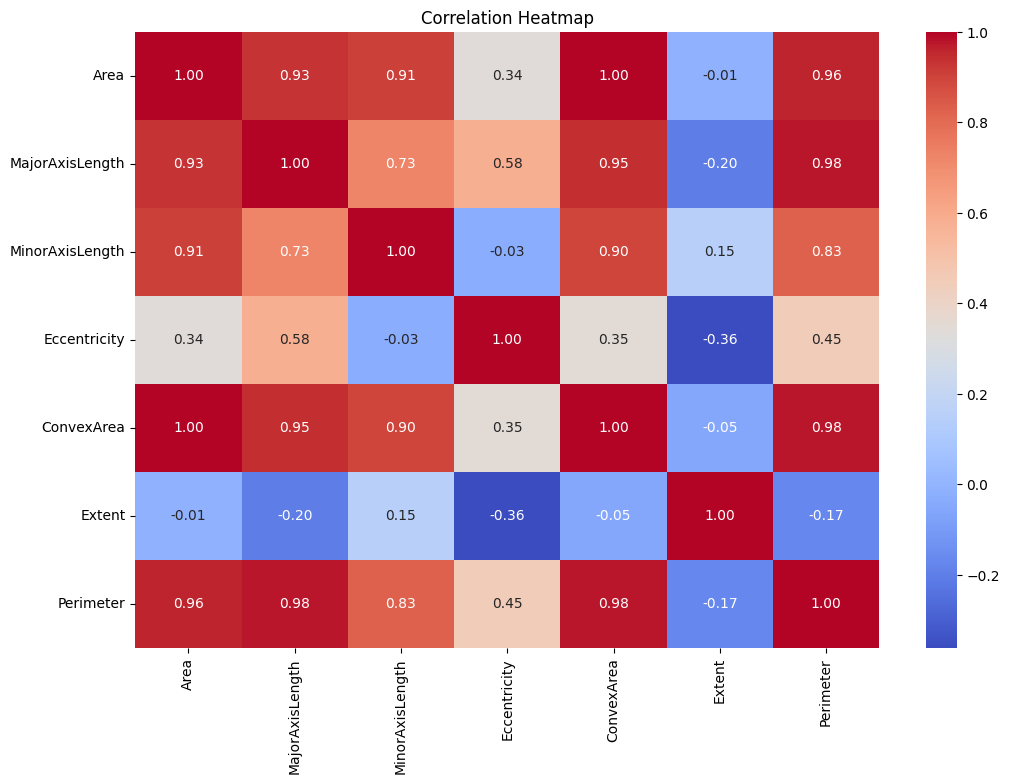

In [25]:
plt.figure(figsize=(12,8))

corr = df[features].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()

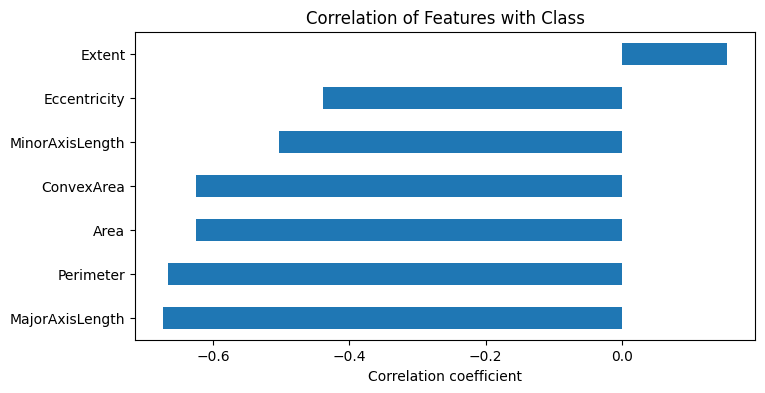

In [26]:
# Correlation of every feature with the class label
class_codes = df[target].astype('category').cat.codes

plt.figure(figsize=(8,4))
df[features].corrwith(class_codes).sort_values().plot(kind='barh')
plt.title('Correlation of Features with Class')
plt.xlabel('Correlation coefficient')
plt.show()

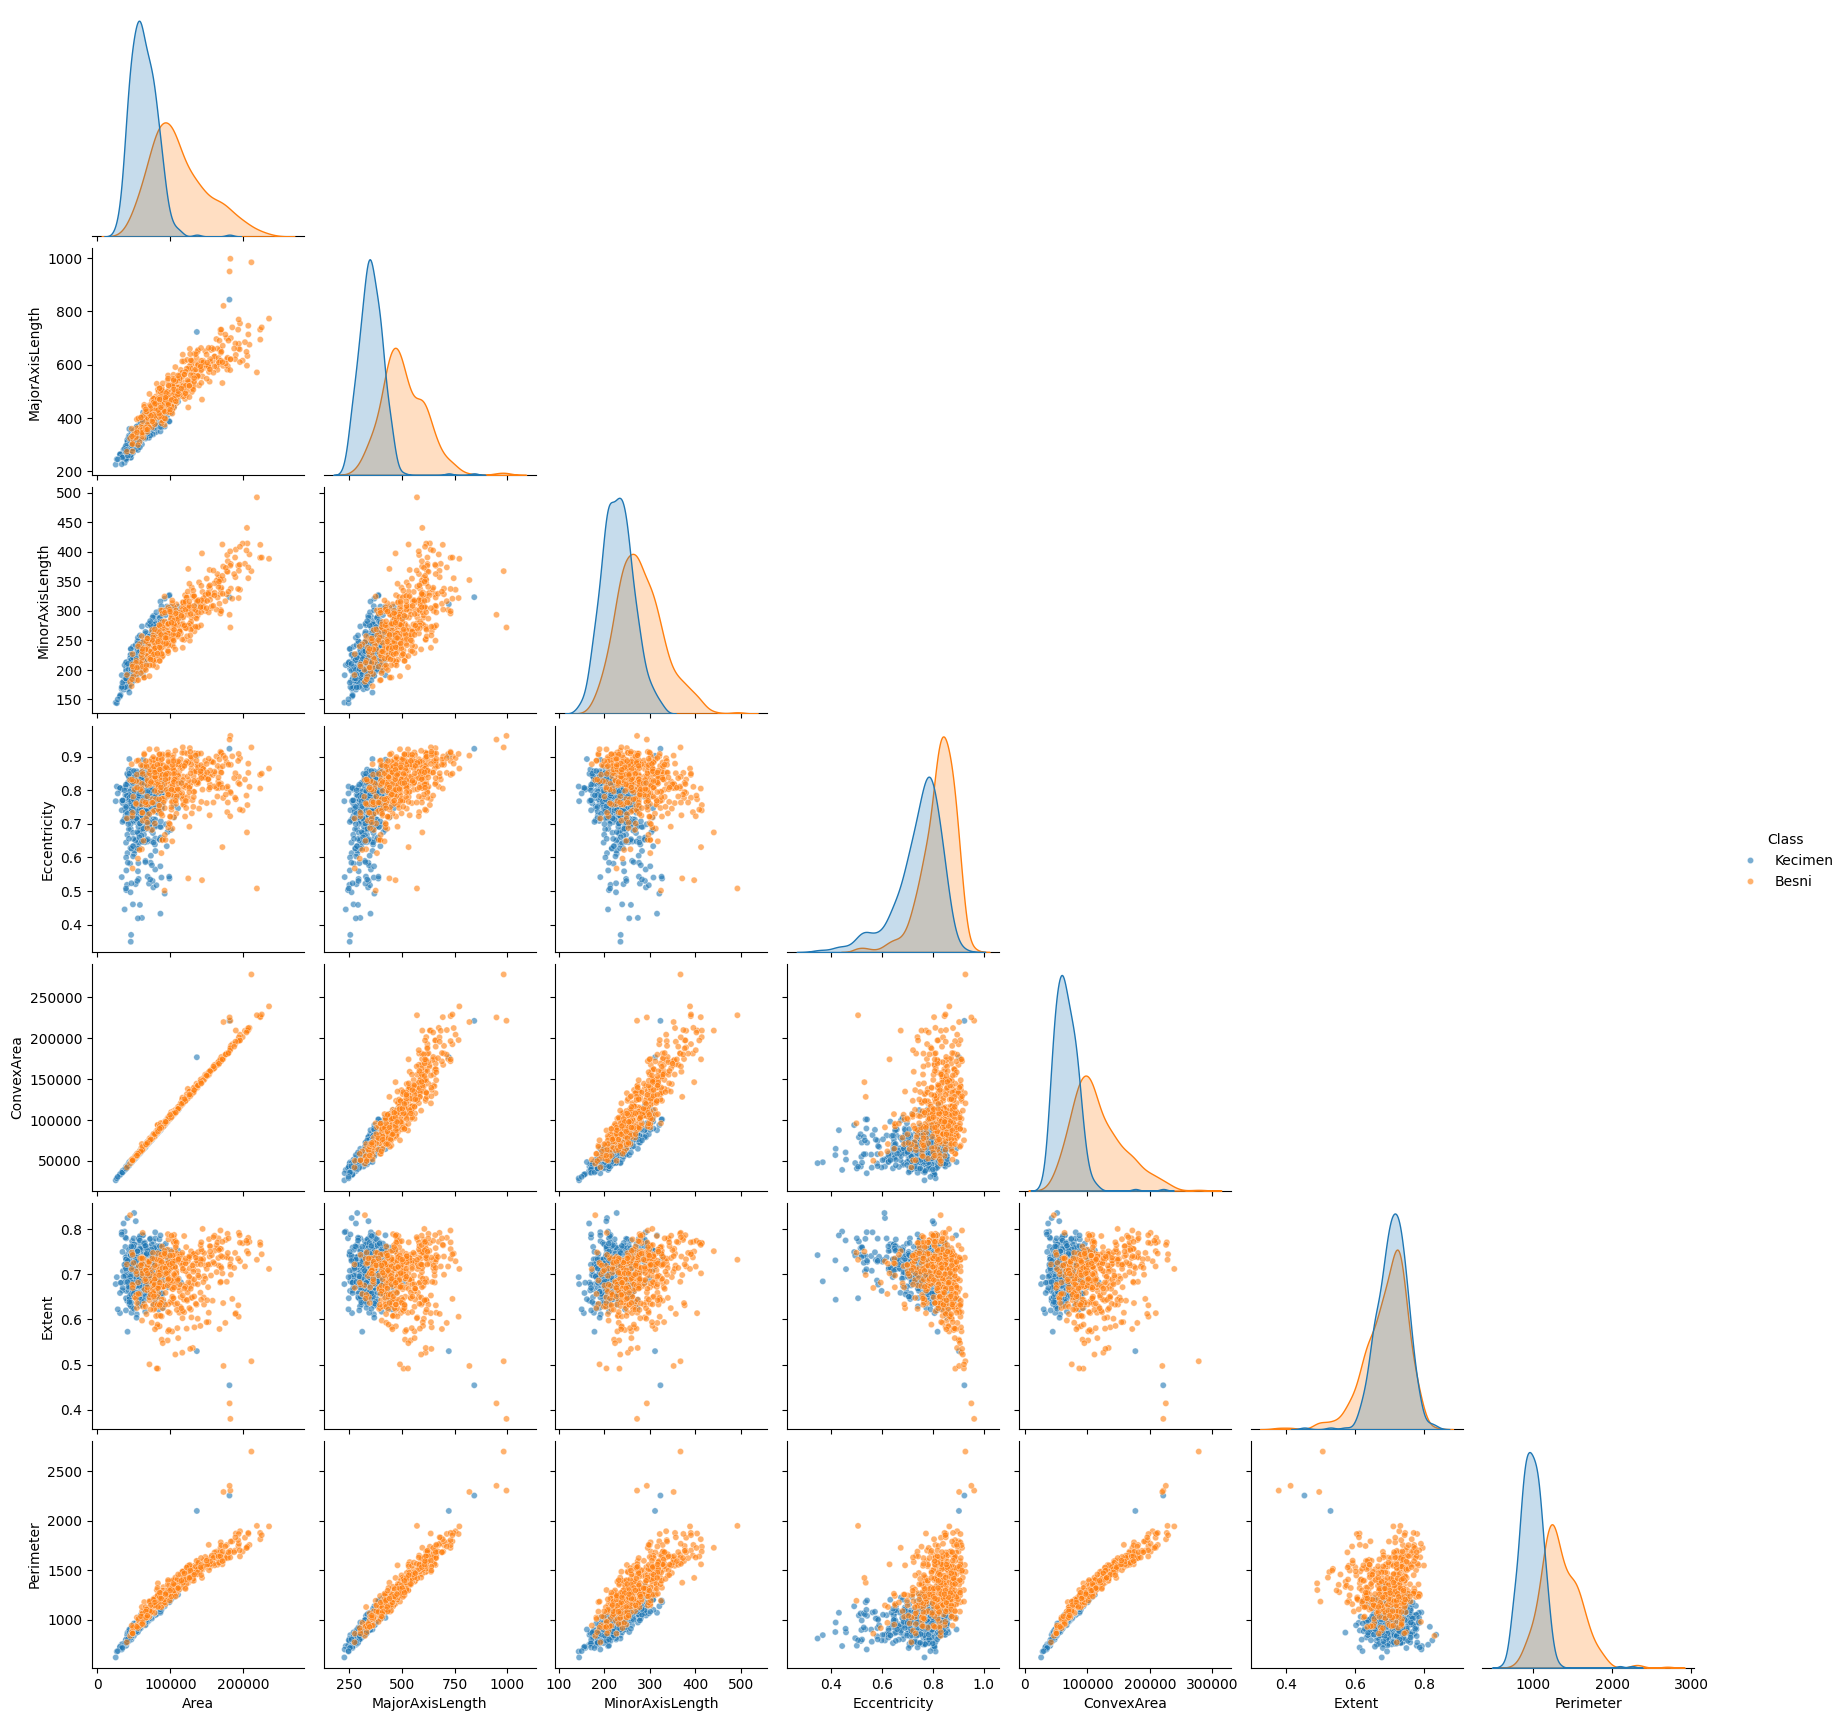

In [28]:
# Pair Plot
sns.pairplot(df[features + [target]], hue=target, corner=True, plot_kws={"s": 20, "alpha": 0.6})

plt.show()

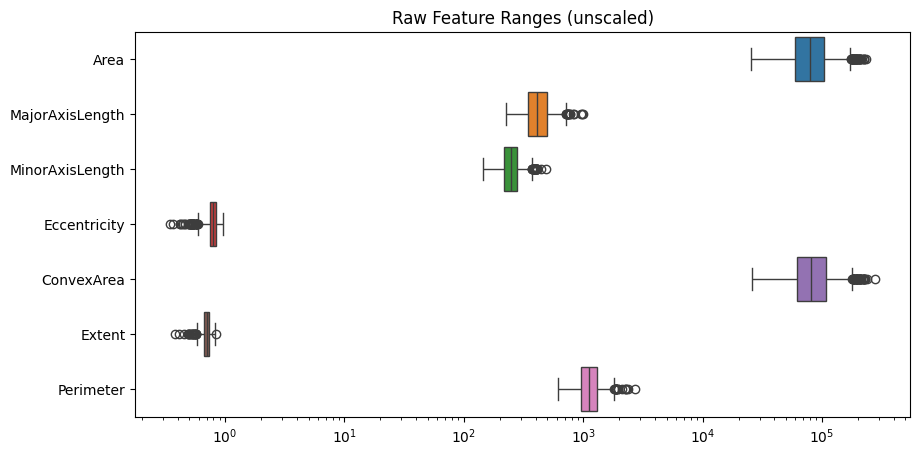

In [29]:
# Feature scale comparison (relevant for distance/gradient based models)
plt.figure(figsize=(10,5))
sns.boxplot(data=df[features], orient='h')
plt.title('Raw Feature Ranges (unscaled)')
plt.xscale('log')
plt.show()

In [30]:
#data pre_proccesing
label_encoder=LabelEncoder()

df["Class_encoded"]=label_encoder.fit_transform(df["Class"])

print(df[["Class","Class_encoded"]].head(5))

     Class  Class_encoded
0  Kecimen              1
1  Kecimen              1
2  Kecimen              1
3  Kecimen              1
4  Kecimen              1


In [31]:
numerical_features=df.select_dtypes(include=np.number).columns

In [32]:
X=df[numerical_features]

y=df["Class_encoded"]

In [33]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

print("Training Samples:",X_train.shape[0])
print("Testing Samples:",X_test.shape[0])

Training Samples: 720
Testing Samples: 180


In [34]:
GaussianNB()

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


In [35]:
gnb=GaussianNB()

gnb.fit(X_train,y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[360.,360.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.5,0.5]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.691
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['Area','MajorAxisLength','MinorAxisLength',...,'Extent','Perimeter', 'Class_encoded']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 8)","[[113429.81, 513.27, 280.59,..., 0.69, 1357.66, 0. ], [ 63707.9 , 353.69, 229.97,..., 0.71, 985.65, 1. ]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 8)","[[1.56e+09,1.17e+04,2.52e+03,...,1.70e+00,6.32e+04,1.69e+00], [2.90e+08,3.10e+03,1.16e+03,...,1.69e+00,1.98e+04,1.69e+00]]"


In [36]:
y_pred=gnb.predict(X_test)

print(y_pred)

[1 0 0 1 0 1 0 1 1 1 1 1 1 1 0 1 1 1 0 0 0 1 1 1 1 1 1 1 1 1 1 1 0 0 1 0 1
 0 0 0 0 0 0 0 0 0 0 1 0 0 1 1 0 1 1 1 0 1 0 0 0 1 1 0 0 1 0 1 1 1 1 0 0 1
 1 1 0 1 0 1 0 1 1 1 1 0 1 1 1 1 0 1 1 0 1 1 1 1 1 0 1 1 1 0 1 0 1 0 1 1 0
 1 1 0 1 0 1 0 0 1 0 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 0 1 1 1 0 1 1 0 0 1
 1 1 1 0 0 1 1 1 0 1 1 0 1 0 0 0 0 1 1 1 1 1 1 0 1 1 1 0 0 1 0 1]


In [37]:
comparison=pd.DataFrame({"Actual":y_test.values,"Predicted":y_pred})
print(comparison.head(5))

   Actual  Predicted
0       0          1
1       0          0
2       0          0
3       1          1
4       0          0


In [38]:
comparison["Actual_Class"]=label_encoder.inverse_transform(comparison["Actual"])

comparison["Predicted_Class"]=label_encoder.inverse_transform(comparison["Predicted"])

print(comparison.head(5))

   Actual  Predicted Actual_Class Predicted_Class
0       0          1        Besni         Kecimen
1       0          0        Besni           Besni
2       0          0        Besni           Besni
3       1          1      Kecimen         Kecimen
4       0          0        Besni           Besni


In [39]:
accuracy=accuracy_score(y_test,y_pred)
print("Accuracy:",accuracy)
precision=precision_score(y_test,y_pred)
print("Precision:", precision)
recall=recall_score(y_test,y_pred)
print("Recall:",recall)
f1=f1_score(y_test,y_pred)
print("f1 score:",f1)

Accuracy: 0.8277777777777777
Precision: 0.7657657657657657
Recall: 0.9444444444444444
f1 score: 0.845771144278607


In [47]:
cm = confusion_matrix(y_test, y_pred)
class_names = label_encoder.classes_   # ['Besni', 'Kecimen']
cm

array([[64, 26],
       [ 5, 85]])

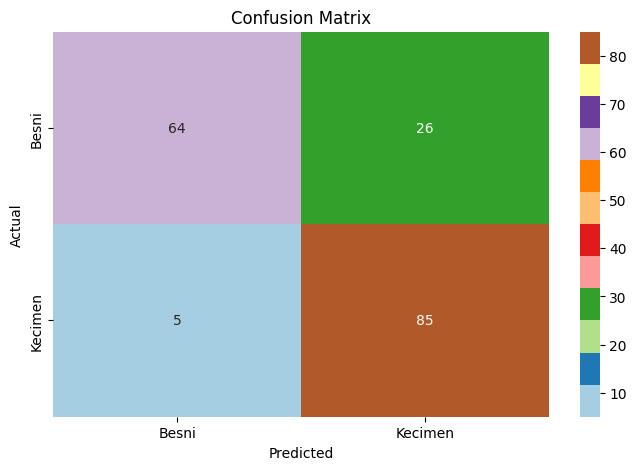

In [48]:
plt.figure(figsize=(8,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Paired",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [41]:
from sklearn.metrics import accuracy_score

y_train_pred=gnb.predict(X_train)
y_test_pred=gnb.predict(X_test)

train_accuracy=accuracy_score(y_train,y_train_pred)
test_accuracy=accuracy_score(y_test,y_test_pred)

print(train_accuracy)
print(test_accuracy)

0.8375
0.8277777777777777


In [42]:
GaussianNB(priors=None)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
